# AgriVision : DINOv3 ViT-S/16 gelé + tête de segmentation sur Agriculture-Vision 2021

**Prérequis (une seule fois)**
1. Demander l'accès au modèle sur https://huggingface.co/facebook/dinov3-vits16-pretrain-lvd1689m (modèle *gated*, accepter la licence DINOv3).
2. Créer un token HF (lecture) sur https://huggingface.co/settings/tokens, puis l'ajouter dans les **Secrets Colab** (icône 🔑) sous le nom `HF_TOKEN`, avec l'accès notebook activé.
3. Runtime → Modifier le type d'exécution → GPU **L4** ou **A100**.

La première exécution télécharge l'archive de 21 Go depuis S3 (bucket public AWS Open Data) et construit un sous-ensemble équilibré, qui est sauvegardé sur Drive. Les sessions suivantes repartent de ce sous-ensemble en quelques minutes.

In [1]:
# --- Configuration ---
DRIVE_DIR = "/content/drive/MyDrive/agrivision"     # sous-ensemble + runs (persistant)
CODE_SOURCE = "git"                                # "drive" : copie depuis CODE_DIR ; "git" : clone REPO_URL
CODE_DIR = f"{DRIVE_DIR}/code"                       # dossier du projet (contient agrivision/)
REPO_URL = "https://github.com/JulesV19/AgriVision.git"

N_TRAIN, N_VAL, N_TEST = 12000, 3000, 2000
RUN_NAME = "vits16_frozen_512"
EPOCHS, BATCH_SIZE, LR = 20, 32, 1e-3
BACKBONE = "facebook/dinov3-vits16-pretrain-lvd1689m"

In [2]:
from google.colab import drive
drive.mount("/content/drive")
import os

def sh(cmd):
    # Comme `!cmd`, mais lève une erreur si la commande échoue (sinon « Exécuter tout » continue).
    ip = get_ipython()
    ip.system(f"set -o pipefail; {cmd}")
    if ip.user_ns.get("_exit_code", 0) != 0:
        raise RuntimeError(f"commande en échec (code {ip.user_ns['_exit_code']}), voir la sortie ci-dessus : {cmd}")

os.makedirs(DRIVE_DIR, exist_ok=True)
if CODE_SOURCE == "git":
    sh(f"rm -rf /content/AgriVision && git clone -q {REPO_URL} /content/AgriVision")
else:
    sh(f'rm -rf /content/AgriVision && cp -r "{CODE_DIR}" /content/AgriVision')
%cd /content/AgriVision
sh("nvidia-smi --query-gpu=name,memory.total --format=csv")

Mounted at /content/drive
/content/AgriVision
name, memory.total [MiB]
NVIDIA L4, 23034 MiB


In [3]:
sh("pip install -q -r requirements.txt")

In [4]:
# Connexion HF + vérification de l'accès au modèle gated
from google.colab import userdata
from huggingface_hub import login
login(token=userdata.get("HF_TOKEN"))
from transformers import AutoConfig
print(AutoConfig.from_pretrained(BACKBONE))

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

DINOv3ViTConfig {
  "apply_layernorm": true,
  "architectures": [
    "DINOv3ViTModel"
  ],
  "attention_dropout": 0.0,
  "drop_path_rate": 0.0,
  "dtype": "float32",
  "hidden_act": "gelu",
  "hidden_size": 384,
  "image_size": 224,
  "initializer_range": 0.02,
  "intermediate_size": 1536,
  "key_bias": false,
  "layer_norm_eps": 1e-05,
  "layerscale_value": 1.0,
  "mlp_bias": true,
  "model_type": "dinov3_vit",
  "num_attention_heads": 6,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "num_register_tokens": 4,
  "out_features": [
    "stage12"
  ],
  "out_indices": [
    12
  ],
  "patch_size": 16,
  "pos_embed_jitter": null,
  "pos_embed_rescale": 2.0,
  "pos_embed_shift": null,
  "proj_bias": true,
  "query_bias": true,
  "reshape_hidden_states": true,
  "rope_theta": 100.0,
  "stage_names": [
    "stem",
    "stage1",
    "stage2",
    "stage3",
    "stage4",
    "stage5",
    "stage6",
    "stage7",
    "stage8",
    "stage9",
    "stage10",
    "stage11",
    "stage12"
  ],
 

## Données
Si un `agv_subset.tar` valide existe sur Drive, on le recopie simplement. Sinon, on télécharge l'archive depuis S3 (aria2, avec progression), on l'extrait sans le test officiel ni le NIR, puis on construit le sous-ensemble. Compter environ 30 à 60 min la première fois.

In [5]:
SUBSET_TAR = f"{DRIVE_DIR}/agv_subset.tar"
DATA = "/content/agv_subset"
S3 = "https://intelinair-data-releases.s3.amazonaws.com/agriculture-vision/cvpr_challenge_2021/supervised/Agriculture-Vision-2021.tar.gz"

RAW = "/content/raw/Agriculture-Vision-2021"

def subset_ok():
    return os.path.exists(f"{DATA}/meta.json")

if not subset_ok() and os.path.exists(SUBSET_TAR):
    print(f"agv_subset.tar sur Drive : {os.path.getsize(SUBSET_TAR) / 1e9:.2f} Go")
    sh(f'tar xf "{SUBSET_TAR}" -C /content || true')
    if not subset_ok():
        print("-> archive invalide ou incomplète (reste d'un run raté) : suppression et reconstruction")
        os.remove(SUBSET_TAR)

if not subset_ok():
    if not os.path.exists("/content/raw/.done"):
        sh("rm -rf /content/raw && mkdir -p /content/raw && df -h /content | tail -1")
        sh("apt-get -qq install -y aria2 pigz > /dev/null")
        # 1) téléchargement parallèle (16 connexions), reprenable (-c), résumé toutes les 15 s
        sh(f"aria2c -x 16 -s 16 -k 64M -c --file-allocation=none --show-console-readout=false "
           f"--summary-interval=15 --console-log-level=warn -d /content -o agv2021.tar.gz {S3}")
        # 2) extraction (sans test officiel ni NIR), un point affiché tous les ~500 Mo lus
        sh("tar -I pigz -xf /content/agv2021.tar.gz -C /content/raw --exclude='*/test/*' --exclude='*/images/nir/*' "
           "--checkpoint=50000 --checkpoint-action=dot")
        sh("rm /content/agv2021.tar.gz && touch /content/raw/.done")
    sh(f"du -sh {RAW}/* && ls {RAW}/train {RAW}/train/labels")
    sh(f"rm -rf {DATA} && python -m agrivision.prepare_subset --src {RAW} --out {DATA} "
       f"--n-train {N_TRAIN} --n-val {N_VAL} --n-test {N_TEST} --workers {os.cpu_count()}")
    # écriture atomique sur Drive : jamais d'archive partielle en cas de coupure
    sh(f'tar cf /content/agv_subset.tar -C /content agv_subset && cp /content/agv_subset.tar "{SUBSET_TAR}.tmp" '
       f'&& mv "{SUBSET_TAR}.tmp" "{SUBSET_TAR}" && rm /content/agv_subset.tar')
sh(f"du -sh {DATA}/* && head -40 {DATA}/meta.json")

overlay         113G   43G   71G  38% /
 *** Download Progress Summary as of Mon Oct 12 09:55:10 2026 *** 
=
[#14c7d1 3.1GiB/19GiB(15%) CN:16 DL:246MiB ETA:1m8s]
FILE: /content/agv2021.tar.gz
-

 *** Download Progress Summary as of Mon Oct 12 09:55:26 2026 *** 
=
[#14c7d1 6.9GiB/19GiB(35%) CN:16 DL:244MiB ETA:53s]
FILE: /content/agv2021.tar.gz
-

 *** Download Progress Summary as of Mon Oct 12 09:55:42 2026 *** 
=
[#14c7d1 10GiB/19GiB(54%) CN:16 DL:243MiB ETA:37s]
FILE: /content/agv2021.tar.gz
-

 *** Download Progress Summary as of Mon Oct 12 09:55:57 2026 *** 
=
[#14c7d1 14GiB/19GiB(72%) CN:16 DL:206MiB ETA:27s]
FILE: /content/agv2021.tar.gz
-

 *** Download Progress Summary as of Mon Oct 12 09:56:13 2026 *** 
=
[#14c7d1 17GiB/19GiB(91%) CN:16 DL:240MiB ETA:7s]
FILE: /content/agv2021.tar.gz
-


Download Results:
gid   |stat|avg speed  |path/URI
======+====+===========+=======================================================
14c7d1|OK  |   216MiB/s|/content/agv2021.tar.gz

Status Legen

## Entraînement
Les checkpoints (`best.pt`, `last.pt`) et `log.jsonl` sont écrits sur Drive. Si la session coupe, il suffit de relancer la cellule : l'entraînement reprend depuis `last.pt`.

In [6]:
RUN = f"{DRIVE_DIR}/runs/{RUN_NAME}"
sh(f'python -m agrivision.train --data {DATA} --out "{RUN}" --backbone {BACKBONE} '
   f'--epochs {EPOCHS} --batch-size {BATCH_SIZE} --lr {LR} --workers {os.cpu_count()}')


model.safetensors: downloading bytes:  47% 40.7M/86.4M [00:01<00:01, 35.1MB/s, 2.01MB/s  ]
model.safetensors: reconstructing file:  43% 36.7M/86.4M [00:01<00:02, 20.1MB/s]
model.safetensors: downloading bytes:  65% 56.6M/86.4M [00:02<00:00, 36.8MB/s, 4.91MB/s  ]
model.safetensors: downloading bytes:  78% 67.6M/86.4M [00:02<00:00, 40.8MB/s, 5.48MB/s  ]
model.safetensors: downloading bytes: 100% 82.4M/82.4M [00:02<00:00, 31.6MB/s, 7.35MB/s  ]
model.safetensors: reconstructing file: 100% 86.4M/86.4M [00:02<00:00, 33.1MB/s, 7.82MB/s  ]
Loading weights: 100% 211/211 [00:00<00:00, 4662.65it/s]
backbone facebook/dinov3-vits16-pretrain-lvd1689m | paramètres entraînables : 1.62 M
epoch 0: 100% 375/375 [03:28<00:00,  1.80it/s, loss=1.7184, lr=9.65e-04]
epoch 0 | loss 1.6950 | val mIoU 0.3006 | backgr=0.73 double=0.00 drydow=0.53 endrow=0.14 nutrie=0.15 plante=0.00 water=0.62 waterw=0.40 weed_c=0.13
epoch 1: 100% 375/375 [03:24<00:00,  1.83it/s, loss=0.9432, lr=9.94e-04]
epoch 1 | loss 0.9401 | 

In [7]:
# Évaluation finale sur le test (parcelles du val officiel jamais vues pendant la sélection)
sh(f'python -m agrivision.train --data {DATA} --out "{RUN}" --backbone {BACKBONE} '
   f'--eval-only --split test --workers {os.cpu_count()}')

Loading weights: 100% 211/211 [00:00<00:00, 3636.13it/s]
backbone facebook/dinov3-vits16-pretrain-lvd1689m | paramètres entraînables : 1.62 M
{
  "split": "test",
  "miou": 0.4292976299187549,
  "iou": {
    "background": 0.7849377300344709,
    "double_plant": 0.31887252873758615,
    "drydown": 0.5176674333141108,
    "endrow": 0.25881767729273136,
    "nutrient_deficiency": 0.28676848725863835,
    "planter_skip": 0.33462366429315904,
    "water": 0.7716940658496241,
    "waterway": 0.36398768444610496,
    "weed_cluster": 0.2263093980423687
  }
}


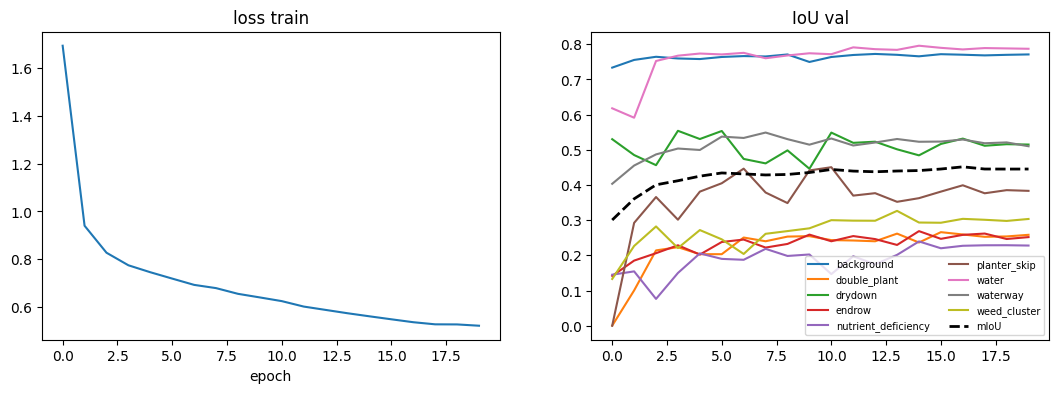

In [8]:
import json, matplotlib.pyplot as plt
log = [json.loads(l) for l in open(f"{RUN}/log.jsonl")]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot([e["loss"] for e in log]); ax[0].set_title("loss train"); ax[0].set_xlabel("epoch")
for c in log[0]["val_iou"]:
    ax[1].plot([e["val_iou"][c] for e in log], label=c)
ax[1].plot([e["val_miou"] for e in log], "k--", lw=2, label="mIoU")
ax[1].set_title("IoU val"); ax[1].legend(fontsize=7, ncol=2); plt.show()

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

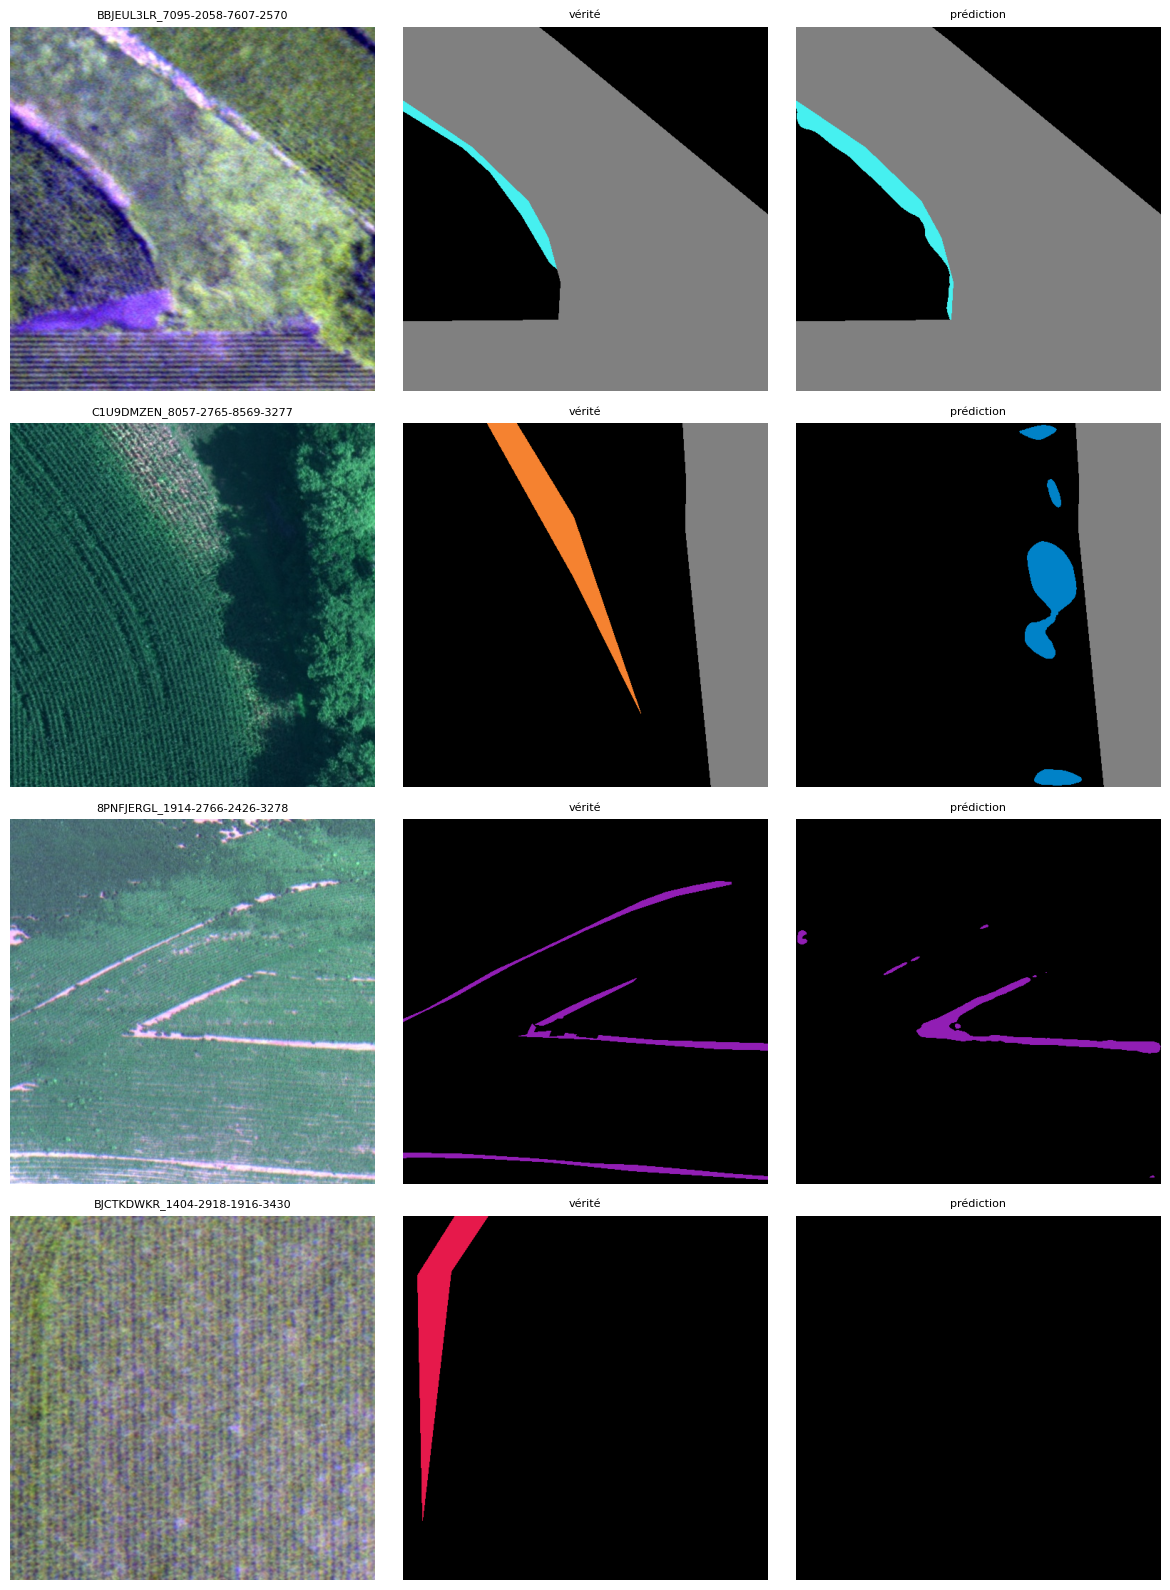

background=(np.uint8(0), np.uint8(0), np.uint8(0))  double_plant=(np.uint8(230), np.uint8(25), np.uint8(75))  drydown=(np.uint8(255), np.uint8(225), np.uint8(25))  endrow=(np.uint8(60), np.uint8(180), np.uint8(75))  nutrient_deficiency=(np.uint8(245), np.uint8(130), np.uint8(48))  planter_skip=(np.uint8(145), np.uint8(30), np.uint8(180))  water=(np.uint8(0), np.uint8(130), np.uint8(200))  waterway=(np.uint8(70), np.uint8(240), np.uint8(240))  weed_cluster=(np.uint8(240), np.uint8(50), np.uint8(230))


In [9]:
# Visualisation : image | vérité terrain | prédiction
import numpy as np, torch
from agrivision import CLASSES, MEAN, STD
from agrivision.data import AgriVisionSubset, decode_labels
from agrivision.model import DinoSegmenter

device = "cuda"
model = DinoSegmenter(len(CLASSES), backbone=BACKBONE).to(device).eval()
model.load_state_dict(torch.load(f"{RUN}/best.pt", map_location=device)["model"], strict=False)
ds = AgriVisionSubset(DATA, "test")

PALETTE = np.array([[0,0,0],[230,25,75],[255,225,25],[60,180,75],[245,130,48],
                    [145,30,180],[0,130,200],[70,240,240],[240,50,230]], np.uint8)

def show(idxs):
    fig, axes = plt.subplots(len(idxs), 3, figsize=(12, 4 * len(idxs)))
    for row, i in zip(axes, idxs):
        img, lbl = ds[i]
        target, valid = decode_labels(lbl[None].to(device), len(CLASSES))
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
            pred = model(img[None].to(device)).argmax(1)[0].cpu().numpy()
        gt = (target[0].float() * torch.arange(len(CLASSES), device=device)[:, None, None]).amax(0).cpu().numpy().astype(int)
        rgb = (img.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)
        inv = ~valid[0].cpu().numpy()
        gt_rgb, pred_rgb = PALETTE[gt], PALETTE[pred]
        gt_rgb[inv] = pred_rgb[inv] = 128
        for a, im, t in zip(row, [rgb, gt_rgb, pred_rgb], [ds.ids[i], "vérité", "prédiction"]):
            a.imshow(im); a.set_title(t, fontsize=8); a.axis("off")
    plt.tight_layout(); plt.show()
    print("  ".join(f"{c}={tuple(PALETTE[k])}" for k, c in enumerate(CLASSES)))

show(np.random.choice(len(ds), 4, replace=False))